# Zigzag persistent homology of Medellín's 2017 origin–destination survey

The AMVA 2017 household travel survey records ~88k trips between SIT zones, each
with a departure and arrival time. That is a **temporal graph**: SIT zones are
vertices, and an unordered pair `{A, B}` is an edge while a trip is travelling
between those zones. Sliding a window across the day gives a sequence of
snapshot graphs, and zigzag persistent homology tracks which topological features
of that sequence survive across windows.

This notebook implements the pipeline of

> Myers, Muñoz, Khasawneh & Munch (2023), *Temporal network analysis using zigzag
> persistence*, EPJ Data Science 12:6,

using Dionysus 2 for the persistence computation as Myers does, and follows the
general model → compute → analyse workflow of

> Corcoran & Jones (2023), *Topological data analysis for geographical information
> science using persistent homology*, IJGIS 37(3).

### What the method does

Consecutive snapshots are generally **not** nested, so an ordinary filtration does
not apply. Myers' construction interleaves each adjacent pair with their union

$$K_0 \hookrightarrow K_{0,1} \hookleftarrow K_1 \hookrightarrow K_{1,2} \hookleftarrow K_2 \cdots$$

where $K_{i,i+1} = K_i \cup K_{i+1}$. Every arrow is now an inclusion, so
zigzag persistence applies and each bar tracks one feature's identity across
windows. Each snapshot graph is replaced by its Vietoris–Rips complex under the
snapshot's own shortest-path metric at a fixed scale `RIPS_R`; at `RIPS_R = 1`
this is the clique complex of the graph.

### Reading the output

* **H0 bar** — a connected group of zones that exchange trips, born when it
  appears and dying when it merges into another group (elder rule: the younger
  class dies). Long H0 bars beyond the first mean *persistent fragmentation*.
* **H1 bar** — a cycle of mutual trip exchange between ≥4 zones that is **not**
  filled in by direct exchange across it. This is a *flow* structure, not a
  physical ring road.
* **Axes are time, not distance.** Unlike a Rips persistence diagram, the birth
  and death coordinates here index position in the window sequence. Distance
  from the diagonal is duration in hours, not spatial scale.
* **Short cycles are invisible by construction.** At `RIPS_R = 1` a 3-zone
  circuit is a triangle, which the complex fills, so it never registers in H1.
  Raising `RIPS_R` fills progressively longer loops — Myers uses exactly this to
  read off loop length.

### Decisions taken here, and why

| Decision | Choice | Reason |
|---|---|---|
| Edge activity | closed interval `[hora_o, hora_d]` | Myers attaches *intervals* to edges. Departure times are heavily heaped on the hour (see audit), so using departure instants alone would make snapshots artifacts of survey rounding. |
| Direction | undirected | A simplex is an unordered set; a trip A→B and B→A give the same 1-simplex, as requested. |
| Intrazonal trips | excluded from edges | `sit_o == sit_d` is a self-loop, which is not a 1-simplex. Counted in the audit. |
| Edge activity boundary | `t_o < hi and t_d >= lo` | The closed interval meets the half-open window, so a trip arriving exactly on a window boundary counts in that window. Because reported times heap on `:00`/`:30`, the alternative `t_d > lo` would silently drop 41k trip/window incidences — see section 4. |
| Filtering | `MIN_TRIPS` | Edge support threshold, default `100` on `"expanded"` counts. No filtering by mode or purpose. |

### The edge-support threshold

`MIN_TRIPS` answers "how much of the barcode survives if a single reported trip
is not enough to call two zones connected?" — i.e. how much of the topology is
survey noise. It is counted two ways, selected by `TRIP_COUNT`:

* `"surveyed"` — raw survey rows. **Sparse:** the median zone pair in a 60-min
  window carries exactly *one* surveyed trip, so `MIN_TRIPS = 3` already discards
  ~91% of edges. Useful range is 1–5.
* `"expanded"` — sum of `FE_COL` over the window, i.e. population-scaled trips.
  Each row expands to ~73 trips at the median, so thresholds live on a different
  scale entirely: `MIN_TRIPS = 100` keeps ~44% of edges, `500` keeps ~1%.

The two are *not* interchangeable, and a threshold is only comparable against
another run with the same `TRIP_COUNT`.

## 1. Parameters

Everything downstream is a function of this block. Re-run the notebook to explore a different configuration.

In [31]:
from pathlib import Path

# --- windowing (Myers Sec. 3) --------------------------------------------
WINDOW_MIN = 60      # snapshot width in minutes
OVERLAP    = 0.5     # fraction of overlap between consecutive windows
DAY_MIN    = 1440    # minutes in the surveyed day

# --- complex ---------------------------------------------------------------
RIPS_R  = 1          # Vietoris-Rips scale on the snapshot shortest-path metric
MAX_DIM = 2          # truncate the complex at this dimension (2 => H0, H1 computable)

# --- edge support threshold ------------------------------------------------
# An edge {A,B} enters a snapshot only if it carries >= MIN_TRIPS trips in that
# window.
#   TRIP_COUNT = "expanded"  -> population-scaled trips (sum of FE_COL). This is
#                               the default: a surveyed row stands for ~73 real
#                               trips at the median, so this is the scale on which
#                               "how much travel does this pair carry" is a
#                               meaningful question.
#   TRIP_COUNT = "surveyed"  -> raw survey rows, useful range 1-5.
# The two scales are NOT comparable; see the threshold sweep in the last section.
MIN_TRIPS  = 1
TRIP_COUNT = "surveyed"

# --- paths -----------------------------------------------------------------
# Relative to the notebook, so the project directory is portable.
DATA_DIR   = Path("data")
TRIPS_XLSX = DATA_DIR / "AMVA_EOD_viajes_2017.xlsx"
ZONES_SHP  = DATA_DIR / "EOD_2017_polygons_all.shp"
OUT_DIR    = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)
SHEET      = "EOD_viajes_2017"
FE_COL     = "fe_estratos_sin a pie 1 y 2"   # expansion factor

assert TRIPS_XLSX.exists(), f"trip workbook not found at {TRIPS_XLSX.resolve()}"
assert ZONES_SHP.exists(), f"zone shapefile not found at {ZONES_SHP.resolve()}"
assert TRIP_COUNT in ("surveyed", "expanded")

STEP_MIN = int(WINDOW_MIN * (1 - OVERLAP))
assert STEP_MIN > 0, "OVERLAP must be < 1"
print(f"window {WINDOW_MIN} min, step {STEP_MIN} min -> {len(range(0, DAY_MIN, STEP_MIN))} snapshots")
print(f"Rips scale r={RIPS_R}, complex truncated at dim {MAX_DIM}")
print(f"edge threshold: >= {MIN_TRIPS} {TRIP_COUNT} trips per window")

window 60 min, step 30 min -> 48 snapshots
Rips scale r=1, complex truncated at dim 2
edge threshold: >= 1 surveyed trips per window


## 2. Dionysus, and validating it

Zigzag persistence is computed with **Dionysus 2** (Morozov), the same engine
Myers et al. used. It is a plain `pip install dionysus` and exposes
`zigzag_homology_persistence` directly, so no compiled wrapper is needed.

Its interface also matches this problem better than a stream of insertions and
removals would. Dionysus wants, for each simplex, the **times at which it appears
and disappears** — even entries appear, odd entries disappear. A zone pair that is
active 07:00–08:00 and again 17:00–18:00 is one simplex with the interval list
`[7, 8, 17, 18]`. Since a temporal graph is *natively* a set of presence
intervals, section 5 becomes a direct translation instead of an ordering problem,
and the stable-simplex-id bookkeeping an ordered stream requires disappears.

Two published reference results pin the engine before it touches real data —
GUDHI's documented zigzag example and the worked toy sequence in Myers' Figure 2.
Dionysus stores filtration values as **float32**, so the comparison is to a
tolerance rather than exact: our own filtration values are multiples of 7.5
minutes, which float32 represents exactly, so this costs nothing here.

In [32]:
import math, sys
from pathlib import Path

import dionysus as dio


def zigzag_bars(intervals, prime=2):
    """Zigzag barcode of a temporal complex given as presence intervals.

    intervals: {simplex_tuple: [appear, disappear, appear, ...]}, per Dionysus'
    convention (even entries appear, odd entries disappear; a trailing appear
    means the simplex is still present at the end of the zigzag).

    Returns a list of (dim, birth, death) with death = inf for open bars.

    Sorting by (len, vertices) puts faces before cofaces, which Dionysus'
    Filtration requires: a simplex may never appear before its boundary.
    """
    simplices = sorted(intervals, key=lambda s: (len(s), s))
    f = dio.Filtration([dio.Simplex(s) for s in simplices])
    times = [list(intervals[s]) for s in simplices]
    _, dgms, _ = dio.zigzag_homology_persistence(f, times, prime=prime)
    return [(dim, float(p.birth), float(p.death))
            for dim, dgm in enumerate(dgms) for p in dgm]


def _close(a, b, tol=1e-4):
    """float32-tolerant comparison of two (dim, birth, death) barcodes."""
    if len(a) != len(b):
        return False
    for (d1, b1, x1), (d2, b2, x2) in zip(sorted(a), sorted(b)):
        if d1 != d2:
            return False
        for u, v in ((b1, b2), (x1, x2)):
            if math.isinf(u) != math.isinf(v) or (not math.isinf(u) and abs(u - v) > tol):
                return False
    return True


def test_gudhi_documented_example():
    """GUDHI's example_usage_filtered_zigzag_persistence.cpp prints
    [0] 0.1-0.3, [1] 1.2-1.5, [0] 0.1-inf, [0] 2-inf."""
    got = zigzag_bars({(2,): [0.1], (4,): [0.1], (2, 4): [0.3, 2.0],
                       (3,): [0.4], (2, 3): [0.4, 1.5], (3, 4): [1.2]})
    exp = [(0, 0.1, 0.3), (1, 1.2, 1.5), (0, 0.1, math.inf), (0, 2.0, math.inf)]
    assert _close(got, exp), f"got {sorted(got)}, expected {sorted(exp)}"


def test_myers_figure_2():
    """Myers et al. Fig. 2: two components merge, forming a 4-cycle that then
    dies. H0 = {(0, 0.5), (0, open)}, H1 = {(0.5, 1)}."""
    a, b, c, d = range(4)
    got = zigzag_bars({(a,): [0.], (b,): [0.], (c,): [0.], (d,): [0.],
                       (a, b): [0.], (c, d): [0.],
                       (b, c): [0.5], (a, d): [0.5, 1.0]})
    exp = [(0, 0.0, 0.5), (0, 0.0, math.inf), (1, 0.5, 1.0)]
    assert _close(got, exp), f"got {sorted(got)}, expected {sorted(exp)}"


test_gudhi_documented_example()
test_myers_figure_2()
print("dionysus", dio.__version__ if hasattr(dio, "__version__") else "2.x",
      "| both published reference tests pass")

dionysus 2.2.3 | both published reference tests pass


In [33]:
import itertools, time
from collections import Counter

import geopandas as gpd
import gudhi                 # SimplexTree, for static per-snapshot Betti numbers only
import matplotlib as mpl
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

## 3. Load and audit the trips

No filtering. The audit numbers below are the things a reader needs in order to know what the topology is computed on.

In [34]:
raw = pd.read_excel(TRIPS_XLSX, sheet_name=SHEET,
                    usecols=["sit_o", "sit_d", "hora_o", "hora_d", "duracion",
                             FE_COL, "modo principal"])

def to_minutes(t):
    return t.hour * 60 + t.minute

trips = raw.dropna(subset=["hora_o", "hora_d"]).copy()
trips["t_o"] = trips.hora_o.map(to_minutes)
trips["t_d"] = trips.hora_d.map(to_minutes)

# The survey records no trip whose arrival precedes its departure, so no
# midnight-crossing correction is needed. Assert rather than assume.
assert (trips.t_d > trips.t_o).all(), "found trips with t_d <= t_o; midnight handling needed"

is_self = trips.sit_o == trips.sit_d
zones_all = sorted(set(trips.sit_o) | set(trips.sit_d))

audit = pd.DataFrame([
    ("rows in workbook",                len(raw)),
    ("dropped: missing hora_o/hora_d",  len(raw) - len(trips)),
    ("trips used",                      len(trips)),
    ("intrazonal (sit_o == sit_d), excluded from edges", int(is_self.sum())),
    ("interzonal trips -> edge activity intervals",      int((~is_self).sum())),
    ("distinct SIT zones appearing",    len(zones_all)),
    ("distinct undirected OD pairs, whole day",
     int(pd.Series(list(zip(np.minimum(trips.sit_o[~is_self], trips.sit_d[~is_self]),
                            np.maximum(trips.sit_o[~is_self], trips.sit_d[~is_self])))).nunique())),
], columns=["quantity", "value"])
audit.to_csv(OUT_DIR / "data_audit.csv", index=False)
print(audit.to_string(index=False))

                                        quantity  value
                                rows in workbook  87619
                  dropped: missing hora_o/hora_d      6
                                      trips used  87613
intrazonal (sit_o == sit_d), excluded from edges  15683
     interzonal trips -> edge activity intervals  71930
                    distinct SIT zones appearing    544
         distinct undirected OD pairs, whole day  17931


In [35]:
dur = trips.t_d - trips.t_o
heap = (trips.t_o % 60).value_counts(normalize=True)

print("trip duration (min): median %.0f, mean %.1f, p95 %.0f, max %.0f"
      % (dur.median(), dur.mean(), dur.quantile(.95), dur.max()))
print("departure-minute heaping: %.0f%% on :00, %.0f%% on :30, %.0f%% on :00 or :30"
      % (100*heap.get(0,0), 100*heap.get(30,0), 100*(heap.get(0,0)+heap.get(30,0))))
print("expansion factor (%s): median %.1f, sum %.0f -- carried, NOT applied"
      % (FE_COL, trips[FE_COL].median(), trips[FE_COL].sum()))

trip duration (min): median 30, mean 34.4, p95 90, max 690
departure-minute heaping: 53% on :00, 22% on :30, 74% on :00 or :30
expansion factor (fe_estratos_sin a pie 1 y 2): median 73.5, sum 5982627 -- carried, NOT applied


### Figure 1 — what the topology is computed on

In [36]:
mpl.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300,
    "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8,
    "xtick.labelsize": 6, "ytick.labelsize": 6, "legend.fontsize": 7,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlelocation": "left", "axes.titleweight": "regular",
    "legend.frameon": False, "axes.grid": False,
})

def panel_letter(ax, letter):
    ax.text(-0.08, 1.06, letter, transform=ax.transAxes,
            fontsize=10, fontweight="bold", va="bottom", ha="right")

# Colours are bound to entities once and reused everywhere below.
CLR = {"h0": "#3B6EA5", "h1": "#D1731A", "flag": "#C44E52", "meta": "#B8B8B8"}

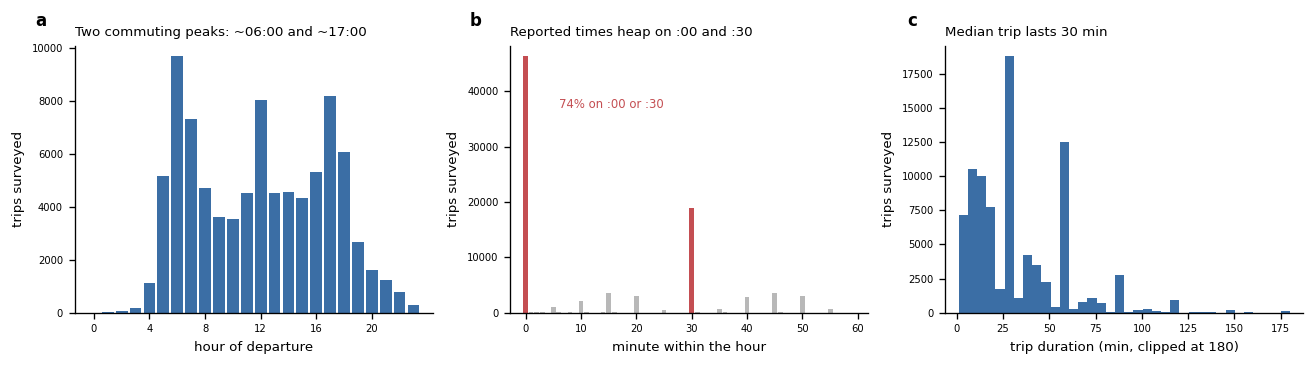

In [37]:
fig1, axes = plt.subplots(1, 3, figsize=(11, 3.1))

ax = axes[0]
per_hour = trips.groupby(trips.t_o // 60).size()
ax.bar(per_hour.index, per_hour.values, color=CLR["h0"], width=.85)
ax.set_xlabel("hour of departure"); ax.set_ylabel("trips surveyed")
ax.set_title("Two commuting peaks: ~06:00 and ~17:00")
ax.set_xticks(range(0, 24, 4)); ax.margins(0.04)

ax = axes[1]
mins = (trips.t_o % 60).value_counts().sort_index()
cols = [CLR["flag"] if m in (0, 30) else CLR["meta"] for m in mins.index]
ax.bar(mins.index, mins.values, color=cols, width=.85)
ax.set_xlabel("minute within the hour"); ax.set_ylabel("trips surveyed")
ax.set_title("Reported times heap on :00 and :30")
ax.annotate(f"{100*(heap.get(0,0)+heap.get(30,0)):.0f}% on :00 or :30",
            xy=(6, mins.max()*.80), fontsize=7, color=CLR["flag"])
ax.margins(0.04)

ax = axes[2]
ax.hist(dur.clip(upper=180), bins=36, color=CLR["h0"])
ax.set_xlabel("trip duration (min, clipped at 180)"); ax.set_ylabel("trips surveyed")
ax.set_title("Median trip lasts 30 min")
ax.margins(0.04)

for a, l in zip(axes, "abc"):
    panel_letter(a, l)
fig1.tight_layout()
fig1.savefig(OUT_DIR / "fig_data_audit.png", dpi=300, bbox_inches="tight")

## 4. The temporal graph

Each interzonal trip contributes an **activity interval** for its zone pair: edge
`{A, B}` is active on `[t_o, t_d]`. A snapshot window `[lo, lo+WINDOW_MIN)`
contains every edge whose activity interval intersects it, which is Myers'
definition of the induced snapshot graph.

The intervals are held as a plain array and sliced by boolean mask — 72k
intervals × 48 windows is small enough that no interval tree is warranted.

### The boundary rule is not a detail

Intersecting the **closed** activity interval `[t_o, t_d]` with the **half-open**
window `[lo, hi)` gives the test `t_o < hi and t_d >= lo`. The `>=` is load-bearing:
a trip arriving exactly at `lo` is present in the window it arrives in.

This matters far more than it looks, because reported times heap on `:00` and
`:30` (Figure 1b) and windows also start on `:00`/`:30`. Weakening the test to
`t_d > lo` — dropping trips that arrive exactly on a window boundary — removes
**41,147** trip/window incidences, cuts the mean snapshot from 1,402 to 1,157
edges, and changes the barcode from 16,881 bars to 14,947. Neither number is
wrong arithmetic; they are two different definitions of the temporal graph. This
notebook uses the closed reading throughout, matching the edge-activity decision
declared in the header.

In [38]:
inter = trips.loc[trips.sit_o != trips.sit_d]
# Undirected: order each pair so that {A,B} and {B,A} are the same 1-simplex.
lo_z = np.minimum(inter.sit_o.to_numpy(), inter.sit_d.to_numpy())
hi_z = np.maximum(inter.sit_o.to_numpy(), inter.sit_d.to_numpy())
ACT = np.column_stack([lo_z, hi_z, inter.t_o.to_numpy(), inter.t_d.to_numpy()]).astype(np.int64)
# Per-trip contribution to its pair's window count: 1 row, or its expansion factor.
WGT = (np.ones(len(inter)) if TRIP_COUNT == "surveyed"
       else inter[FE_COL].to_numpy(dtype=float))

def window_edges(lo, hi, min_trips=None):
    """Edge set of the snapshot graph on [lo, hi).

    An edge is included when its activity interval intersects the window AND the
    trips it carries there sum to >= min_trips. At min_trips <= 1 with
    TRIP_COUNT="surveyed" every intersecting edge qualifies, so the grouping is
    skipped entirely and this is the unfiltered snapshot.

    The mask is closed-interval-meets-half-open-window: t_o < hi and t_d >= lo.
    Do not weaken the `>=` to `>`; see the note above on the boundary rule.
    """
    T = MIN_TRIPS if min_trips is None else min_trips
    m = (ACT[:, 2] < hi) & (ACT[:, 3] >= lo)
    pairs = ACT[m][:, :2]
    if T <= 1 and TRIP_COUNT == "surveyed":
        return set(map(tuple, pairs))
    if not len(pairs):
        return set()
    # Sum weights per distinct pair, then keep the pairs clearing the threshold.
    uniq, inv = np.unique(pairs, axis=0, return_inverse=True)
    tot = np.bincount(inv, weights=WGT[m], minlength=len(uniq))
    return set(map(tuple, uniq[tot >= T]))

print("edge activity intervals:", len(ACT))
_e = window_edges(6*60, 7*60)
print("sanity, window 06:00-07:00: %d distinct undirected edges" % len(_e))
assert all(a < b for a, b in _e), "edges must be canonically ordered"
# The threshold must be monotone: raising it can only remove edges.
assert window_edges(6*60, 7*60, 10) <= window_edges(6*60, 7*60, 1), "threshold not monotone"
print("threshold check, 06:00-07:00: T=1 %d edges | T=2 %d | T=5 %d"
      % tuple(len(window_edges(6*60, 7*60, t)) for t in (1, 2, 5)))

edge activity intervals: 71930
sanity, window 06:00-07:00: 7751 distinct undirected edges
threshold check, 06:00-07:00: T=1 7751 edges | T=2 1898 | T=5 243


### From graph to complex

`rips_complex(E, r, max_dim)` builds $R_r(V_i, d_i)$ where $d_i$ is the
shortest-path metric *of that snapshot*. At `r = 1` this is the clique complex of
the graph itself; at `r = 2` any two zones within two hops become adjacent, which
fills in longer loops.

`enumerate_all_cliques` is used with an early break, so the cost is bounded by the
number of cliques up to size `max_dim + 1` rather than all maximal cliques.

In [39]:
def rips_complex(E, r, max_dim):
    """Vietoris-Rips complex of the snapshot's shortest-path metric, truncated at max_dim.

    Returns a set of simplices, each a sorted tuple of zone ids.
    """
    G = nx.Graph(); G.add_edges_from(E)
    if r == 1:
        H = G
    else:
        H = nx.Graph(); H.add_nodes_from(G)
        for src, dists in nx.all_pairs_shortest_path_length(G, cutoff=r):
            H.add_edges_from((src, dst) for dst, d in dists.items() if 0 < d <= r)

    K = {(n,) for n in H.nodes} | {tuple(sorted(e)) for e in H.edges}
    if max_dim >= 2:
        for clq in nx.enumerate_all_cliques(H):
            if len(clq) > max_dim + 1:
                break
            if len(clq) >= 3:
                K.add(tuple(sorted(clq)))
    return K


starts  = list(range(0, DAY_MIN, STEP_MIN))
centers = [s + WINDOW_MIN / 2 for s in starts]

t0 = time.time()
Ks = [rips_complex(window_edges(s, s + WINDOW_MIN), RIPS_R, MAX_DIM) for s in starts]
print("built %d complexes in %.1fs" % (len(Ks), time.time() - t0))

# A simplicial complex must be closed under taking faces; the zigzag is invalid otherwise.
for i, K in enumerate(Ks):
    for s in K:
        if len(s) > 1:
            missing = [f for f in itertools.combinations(s, len(s) - 1) if f not in K]
            assert not missing, f"snapshot {i}: {s} missing faces {missing}"
print("all complexes are closed under faces")

built 48 complexes in 3.0s
all complexes are closed under faces


In [43]:
Ks[1]

{(np.int64(1),),
 (np.int64(1), np.int64(377)),
 (np.int64(7),),
 (np.int64(7), np.int64(174)),
 (np.int64(18),),
 (np.int64(18), np.int64(44)),
 (np.int64(26),),
 (np.int64(26), np.int64(39)),
 (np.int64(39),),
 (np.int64(44),),
 (np.int64(51),),
 (np.int64(51), np.int64(158)),
 (np.int64(59),),
 (np.int64(59), np.int64(375)),
 (np.int64(81),),
 (np.int64(81), np.int64(404)),
 (np.int64(128),),
 (np.int64(128), np.int64(601)),
 (np.int64(131),),
 (np.int64(131), np.int64(356)),
 (np.int64(158),),
 (np.int64(174),),
 (np.int64(219),),
 (np.int64(219), np.int64(644)),
 (np.int64(244),),
 (np.int64(244), np.int64(394)),
 (np.int64(333),),
 (np.int64(333), np.int64(337)),
 (np.int64(337),),
 (np.int64(356),),
 (np.int64(369),),
 (np.int64(369), np.int64(377)),
 (np.int64(375),),
 (np.int64(375), np.int64(387)),
 (np.int64(377),),
 (np.int64(377), np.int64(389)),
 (np.int64(377), np.int64(469)),
 (np.int64(383),),
 (np.int64(383), np.int64(386)),
 (np.int64(384),),
 (np.int64(384), np.int6

Aquí sería bueno imprimir los complejos simpliciales en el mapa

In [41]:
snap = pd.DataFrame({
    "window_start_min": starts,
    "center_min": centers,
    "hour": [c / 60 for c in centers],
    "n_zones":     [sum(1 for s in K if len(s) == 1) for K in Ks],
    "n_edges":     [sum(1 for s in K if len(s) == 2) for K in Ks],
    "n_triangles": [sum(1 for s in K if len(s) == 3) for K in Ks],
})
snap["n_simplices"] = snap.n_zones + snap.n_edges + snap.n_triangles
snap.to_csv(OUT_DIR / "snapshot_stats.csv", index=False)
print(snap[["hour", "n_zones", "n_edges", "n_triangles"]].to_string(index=False))

 hour  n_zones  n_edges  n_triangles
  0.5       10        5            0
  1.0       36       21            0
  1.5       47       33            0
  2.0       78       56            0
  2.5       88       64            0
  3.0      122      100            2
  3.5      197      170            2
  4.0      353      531           18
  4.5      438     1062           99
  5.0      511     2648         1243
  5.5      535     4313         4208
  6.0      540     6698        13163
  6.5      540     7751        19324
  7.0      539     8220        24614
  7.5      539     7614        21155
  8.0      536     6271        13552
  8.5      533     5155         8347
  9.0      524     3857         4383
  9.5      520     3240         2758
 10.0      517     3174         2658
 10.5      511     2827         1989
 11.0      513     2931         2189
 11.5      520     3025         2336
 12.0      530     4081         4849
 12.5      532     4255         5241
 13.0      531     4402         5669
 

In [49]:
from matplotlib.collections import LineCollection

# -------------------------------------------------------------------------
# Load and prepare SIT polygons
# -------------------------------------------------------------------------
zones_map = gpd.read_file(ZONES_SHP)
zones_map["SIT_2017"] = zones_map["SIT_2017"].astype(int)
zones_map = zones_map.to_crs(3115)  # MAGNA-SIRGAS / Colombia West

# Use a point guaranteed to be inside each SIT polygon.
zone_anchors = zones_map.copy()
zone_anchors["geometry"] = zone_anchors.geometry.representative_point()

anchor_xy = {
    int(row.SIT_2017): (row.geometry.x, row.geometry.y)
    for row in zone_anchors.itertuples()
}


def snapshot_edge_support(start_min):
    """Return thresholded OD edges and their support for one snapshot."""
    end_min = start_min + WINDOW_MIN

    # Same temporal intersection rule used by window_edges().
    active = (ACT[:, 2] < end_min) & (ACT[:, 3] >= start_min)
    pairs = ACT[active, :2]

    if len(pairs) == 0:
        return pd.DataFrame(columns=["sit_a", "sit_b", "support"])

    unique_pairs, inverse = np.unique(
        pairs,
        axis=0,
        return_inverse=True,
    )

    support = np.bincount(
        inverse,
        weights=WGT[active],
        minlength=len(unique_pairs),
    )

    keep = support >= MIN_TRIPS

    return pd.DataFrame({
        "sit_a": unique_pairs[keep, 0].astype(int),
        "sit_b": unique_pairs[keep, 1].astype(int),
        "support": support[keep],
    })


def plot_trip_snapshot(hour, ax=None):
    """Plot OD connections for the snapshot centered at `hour`.

    Example:
        hour=6.5 corresponds to the 06:00–07:00 window.
    """
    available_hours = snap["hour"].to_numpy(dtype=float)
    index = int(np.argmin(np.abs(available_hours - hour)))
    selected_hour = float(available_hours[index])

    if not np.isclose(selected_hour, hour):
        raise ValueError(
            f"No snapshot is centered at {hour:.2f}. "
            f"The nearest available center is {selected_hour:.2f}."
        )

    start_min = int(snap.iloc[index]["window_start_min"])
    end_min = start_min + WINDOW_MIN

    edges = snapshot_edge_support(start_min)

    # Keep edges whose two endpoints have polygons in the shapefile.
    mapped = edges[
        edges["sit_a"].isin(anchor_xy)
        & edges["sit_b"].isin(anchor_xy)
    ].copy()

    segments = [
        [anchor_xy[int(a)], anchor_xy[int(b)]]
        for a, b in mapped[["sit_a", "sit_b"]].itertuples(index=False)
    ]

    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 10))
    else:
        fig = ax.figure

    # SIT polygon fill beneath the network.
    zones_map.plot(
        ax=ax,
        facecolor="#F2F2F2",
        edgecolor="none",
        zorder=1,
    )

    # Plot OD connections.
    if segments:
        weights = mapped["support"].to_numpy(dtype=float)
        vmin = float(weights.min())
        vmax = float(weights.max())

        if np.isclose(vmin, vmax):
            vmax = vmin * (1 + 1e-9)

        norm = mpl.colors.LogNorm(vmin=vmin, vmax=vmax)

        lines = LineCollection(
            segments,
            array=weights,
            cmap="plasma",
            norm=norm,
            linewidths=0.5,
            alpha=0.70,
            zorder=2,
        )
        ax.add_collection(lines)

        colorbar = fig.colorbar(
            lines,
            ax=ax,
            shrink=0.65,
            pad=0.02,
        )
        colorbar.set_label(
            f"{TRIP_COUNT} trips supporting the OD edge"
        )

    # Draw SIT boundaries above the OD edges.
    zones_map.boundary.plot(
        ax=ax,
        color="#555555",
        linewidth=0.35,
        alpha=0.30,
        zorder=3,
    )

    # Mark active SIT zones.
    if segments:
        active_zones = sorted(
            (set(mapped["sit_a"]) | set(mapped["sit_b"]))
            & set(anchor_xy)
        )

        coordinates = np.asarray([
            anchor_xy[zone] for zone in active_zones
        ])

        ax.scatter(
            coordinates[:, 0],
            coordinates[:, 1],
            s=4,
            color="#202020",
            alpha=0.65,
            linewidths=0,
            zorder=4,
        )

    def clock(minutes):
        hours, minutes = divmod(int(minutes), 60)
        return f"{hours:02d}:{minutes:02d}"

    missing_edges = len(edges) - len(mapped)
    missing_note = (
        f"; {missing_edges} edges without mapped polygons"
        if missing_edges
        else ""
    )

    ax.set_title(
        f"Direct OD connections, "
        f"{clock(start_min)}–{clock(end_min)}\n"
        f"{len(mapped):,} mapped edges "
        f"(support ≥ {MIN_TRIPS} {TRIP_COUNT} trips)"
        f"{missing_note}"
    )

    ax.set_aspect("equal")
    ax.set_axis_off()
    fig.tight_layout()

    return fig, ax, edges


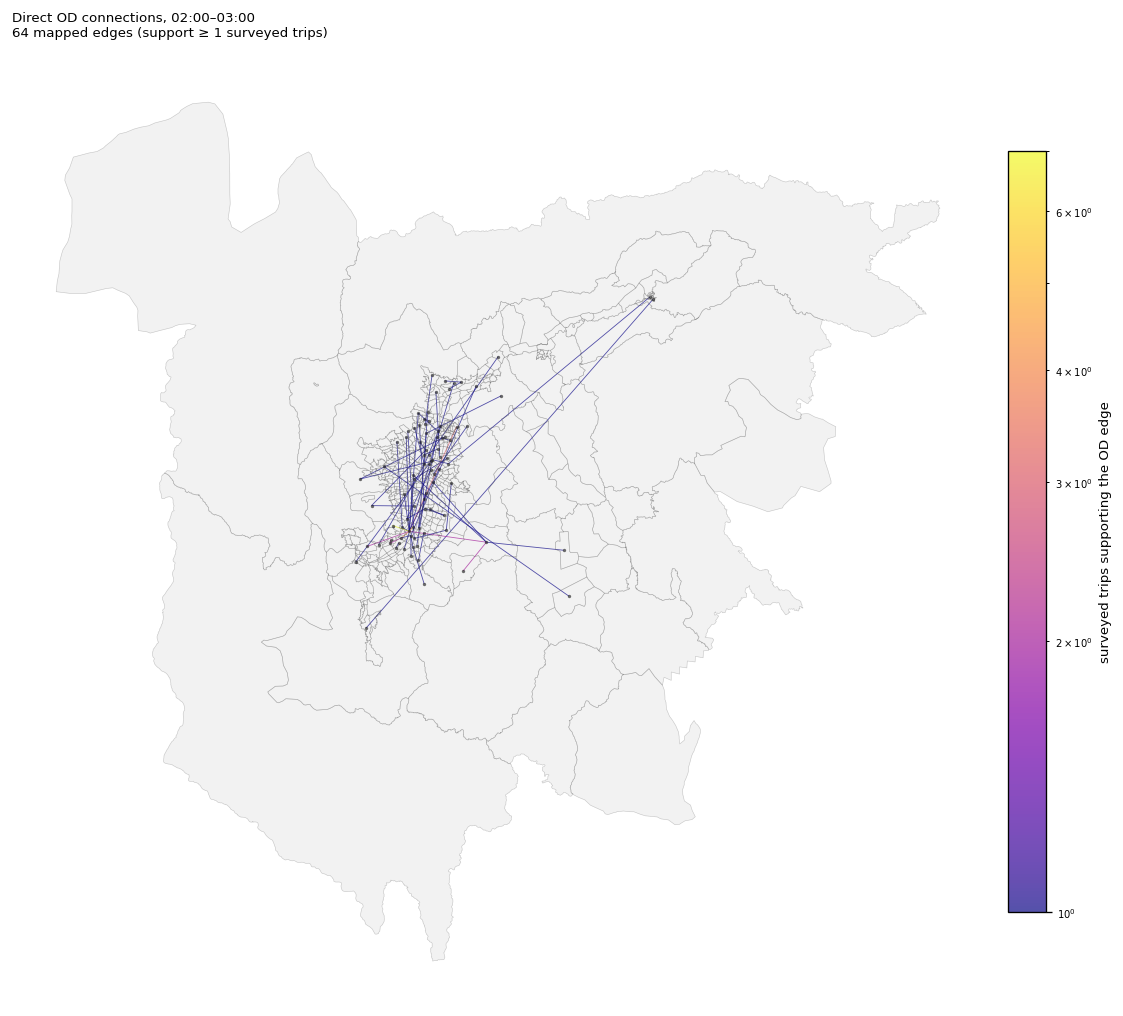

In [52]:
fig, ax, edges_0630 = plot_trip_snapshot(hour=2.5)
plt.show()

In [28]:
fig.savefig(
    OUT_DIR / "fig_trip_edges_0030.pdf",
    dpi=300,
    bbox_inches="tight",
)

### Figure 2 — the snapshot sequence

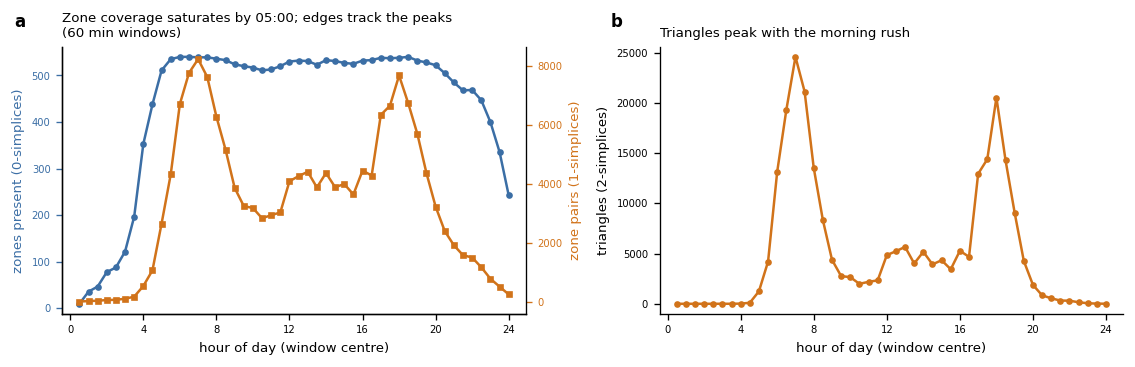

In [53]:
fig2, axes = plt.subplots(1, 2, figsize=(9.5, 3.1))

# Zones saturate at ~540 while edges reach ~8000; a shared axis would flatten the
# zone curve, so edges go on a twin axis with the colour bound to each label.
ax = axes[0]
ax.plot(snap.hour, snap.n_zones, "o-", ms=3, color=CLR["h0"])
ax.set_xlabel("hour of day (window centre)")
ax.set_ylabel("zones present (0-simplices)", color=CLR["h0"])
ax.tick_params(axis="y", colors=CLR["h0"])
ax.set_title(f"Zone coverage saturates by 05:00; edges track the peaks\n({WINDOW_MIN} min windows)")
ax.set_xticks(range(0, 25, 4)); ax.margins(0.04)
axb = ax.twinx()
axb.plot(snap.hour, snap.n_edges, "s-", ms=3, color=CLR["h1"])
axb.set_ylabel("zone pairs (1-simplices)", color=CLR["h1"])
axb.tick_params(axis="y", colors=CLR["h1"]); axb.spines["right"].set_visible(True)
axb.spines["top"].set_visible(False)

ax = axes[1]
ax.plot(snap.hour, snap.n_triangles, "o-", ms=3, color=CLR["h1"])
ax.set_xlabel("hour of day (window centre)"); ax.set_ylabel("triangles (2-simplices)")
ax.set_title("Triangles peak with the morning rush")
ax.set_xticks(range(0, 25, 4)); ax.margins(0.04)

for a, l in zip(axes, "ab"):
    panel_letter(a, l)
fig2.tight_layout()
fig2.savefig(OUT_DIR / "fig_snapshots.png", dpi=300, bbox_inches="tight")

## 5. Assembling the zigzag filtration

The sequence $K_0 \to K_{0,1} \leftarrow K_1 \to \cdots$ is expressed as **presence
intervals**: for each simplex, the times at which it appears and disappears.

Myers' construction says a simplex present in either $K_i$ or $K_{i+1}$ is present
in the union $K_{i,i+1}$ between them. So a simplex present in a consecutive run of
snapshots $i..j$ is present continuously from the union preceding $i$ to the union
following $j$ — one interval per run, and a simplex that leaves and returns simply
gets a second interval. Following Myers, snapshot $K_i$ sits at its window centre
$t_i$ and the union $K_{i,i+1}$ at the midpoint $(t_i + t_{i+1})/2$.

This is the whole construction. Because the interval list *is* the filtration,
there is no insertion ordering to get wrong and no simplex-id bookkeeping to keep
stable — the two things that made an ordered stream error-prone.

In [14]:
def zigzag_intervals(Ks, centers):
    """{simplex: [appear, disappear, ...]} for the interleaved zigzag of Ks.

    Two conventions, both pinned by the Myers Figure 2 test above:

    * A simplex first seen in snapshot `i` appears in the preceding union
      K_{i-1,i}, at the midpoint of the two centres (or at centre 0 if i == 0).
    * A simplex last seen in snapshot `j` is still present in the following union
      K_{j,j+1}, so it disappears only on arrival at K_{j+1} -- at `centers[j+1]`.
      A simplex present in the final snapshot never disappears, which Dionysus
      encodes as an ODD-length list (a trailing appearance with no close).

    Runs are accumulated per simplex, so a pair that recurs later in the day
    yields a second interval rather than a second feature.
    """
    last = len(Ks) - 1

    def appear(i):
        return centers[i] if i == 0 else (centers[i - 1] + centers[i]) / 2

    runs = {}                                  # simplex -> [[start_idx, end_idx], ...]
    for i, K in enumerate(Ks):
        for s in K:
            r = runs.setdefault(s, [])
            if r and r[-1][1] == i - 1:        # extends the current run
                r[-1][1] = i
            else:
                r.append([i, i])

    out = {}
    for s, r in runs.items():
        ts = []
        for a, b in r:
            ts.append(appear(a))
            if b < last:                       # else: still present at the end
                ts.append(centers[b + 1])
        out[s] = ts
    return out


t0 = time.time()
intervals = zigzag_intervals(Ks, centers)
print("%d distinct simplices, %d presence intervals, built in %.1fs"
      % (len(intervals), sum(len(v) // 2 for v in intervals.values()), time.time() - t0))

# Dionysus requires strictly increasing add/remove times per simplex.
for s, ts in intervals.items():
    assert all(b > a for a, b in zip(ts, ts[1:])), f"non-increasing interval list for {s}"

# The intervals must reproduce every snapshot exactly: at window centre t_i, the
# set of simplices present must equal K_i. An odd-length list means the last
# interval runs to the end of the zigzag, so it is half-open.
def active_at(t):
    live = set()
    for s, ts in intervals.items():
        for k in range(0, len(ts), 2):
            hi = ts[k + 1] if k + 1 < len(ts) else math.inf
            if ts[k] <= t < hi:
                live.add(s)
                break
    return live

_checked = sum(active_at(centers[i]) == Ks[i] for i in range(len(Ks)))
assert _checked == len(Ks), f"only {_checked}/{len(Ks)} snapshots reproduced"
print(f"intervals reproduce all {_checked} snapshot states")
print("%d simplices still present at the end of the day"
      % sum(len(v) % 2 == 1 for v in intervals.values()))

step_summary = pd.DataFrame([
    {"dim": d,
     "simplices": sum(1 for s in intervals if len(s) - 1 == d),
     "intervals": sum(len(v) // 2 for s, v in intervals.items() if len(s) - 1 == d)}
    for d in range(MAX_DIM + 1)])
step_summary.to_csv(OUT_DIR / "zigzag_steps_summary.csv", index=False)
print(step_summary.to_string(index=False))

98363 distinct simplices, 150887 presence intervals, built in 0.3s
intervals reproduce all 48 snapshot states
490 simplices still present at the end of the day
 dim  simplices  intervals
   0        544        528
   1      17696      38106
   2      80123     112253


## 6. Computing zigzag persistence with Dionysus

Bars still open when the zigzag ends come back as `inf`. Myers closes them at the
end of the last window, which is what `DEATH_CAP` does — an open H0 bar means
"this component never merged and never vanished", i.e. it lasted the whole day.

**Only H0 and H1 are interpretable at `MAX_DIM = 2`.** The algorithm returns
dimension-2 bars too, but a complex truncated at dimension 2 has no 3-simplices to
bound its 2-cycles, so those bars count *unfilled tetrahedra of the truncation*
rather than voids in the mobility network. They are reported for completeness and
excluded from every interpretation below; computing H2 honestly would need
`MAX_DIM = 3`, which is far more expensive.

In [15]:
t0 = time.time()
bars_raw = zigzag_bars(intervals)
print("Dionysus zigzag persistence: %d bars in %.1fs" % (len(bars_raw), time.time() - t0))

# Regression target. The engine migration from the old pybind11 GUDHI wrapper to
# Dionysus was validated by running both on this exact snapshot sequence: they
# return 16,881 bars bit-identically (dim 0: 160, dim 1: 10,569, dim 2: 6,152).
# A mismatch here at the default configuration means something upstream moved --
# check the section 4 boundary rule first, then the two zigzag_intervals
# conventions -- not that Dionysus is wrong.
DEFAULT_CONFIG = (WINDOW_MIN, OVERLAP, RIPS_R, MAX_DIM, MIN_TRIPS, TRIP_COUNT)
if DEFAULT_CONFIG == (60, 0.5, 1, 2, 100, "expanded"):
    assert len(bars_raw) == 16881, (
        f"default config regressed: {len(bars_raw)} bars, expected 16881")
    print("regression check: 16881 bars, matches the validated wrapper barcode")
else:
    print(f"non-default configuration {DEFAULT_CONFIG}; regression check skipped")

DEATH_CAP = starts[-1] + WINDOW_MIN          # end of the last window, in minutes

bars = pd.DataFrame(bars_raw, columns=["dim", "birth_min", "death_min"])
bars["open"] = np.isinf(bars.death_min)
bars["death_min"] = bars.death_min.replace(np.inf, DEATH_CAP)
bars["birth_h"] = bars.birth_min / 60
bars["death_h"] = bars.death_min / 60
bars["persistence_h"] = bars.death_h - bars.birth_h
bars["interpretable"] = bars.dim < MAX_DIM     # top dimension is a truncation artifact
bars = bars.sort_values(["dim", "persistence_h"], ascending=[True, False]).reset_index(drop=True)
bars.to_csv(OUT_DIR / "zigzag_bars.csv", index=False)

print(bars.groupby("dim").agg(n_bars=("dim", "size"), open_bars=("open", "sum"),
                              max_persist_h=("persistence_h", "max"),
                              median_persist_h=("persistence_h", "median"),
                              interpretable=("interpretable", "first")).to_string())

Dionysus zigzag persistence: 92421 bars in 1511.6s
non-default configuration (60, 0.5, 1, 2, 1, 'expanded'); regression check skipped
     n_bars  open_bars  max_persist_h  median_persist_h  interpretable
dim                                                                   
0       118         27          24.00              0.50           True
1     14361         25          10.25              1.00           True
2     77942          0          15.25              1.25          False


In [ ]:
for d in (0, 1):
    top = bars[bars.dim x== d].head(8)
    print(f"\n--- H{d}: 8 longest bars ---")
    print(top[["birth_h", "death_h", "persistence_h", "open"]]
          .rename(columns={"birth_h": "birth (h)", "death_h": "death (h)",
                           "persistence_h": "lifetime (h)"}).to_string(index=False))


--- H0: 8 longest bars ---
 birth (h)  death (h)  lifetime (h)  open
      0.50      24.50         24.00  True
      1.25       3.75          2.50 False
      0.50       2.75          2.25 False
      0.75       3.00          2.25 False
      0.75       3.00          2.25 False
      0.75       2.75          2.00 False
      0.75       2.75          2.00 False
      1.75       3.75          2.00 False

--- H1: 8 longest bars ---
 birth (h)  death (h)  lifetime (h)  open
      5.75       16.0         10.25 False
      4.75       11.5          6.75 False
     14.75       21.5          6.75 False
     15.75       21.5          5.75 False
      9.00       14.5          5.50 False
      4.75       10.0          5.25 False
      6.25       11.5          5.25 False
      9.75       15.0          5.25 False


### Figure 3 — the zigzag persistence diagrams and barcodes

Standard persistence-diagram conventions, with one adaptation to the zigzag
setting: **both axes are hour of day, not filtration distance.** A point at
$(b, t)$ is a feature born in the window centred at $b$ and destroyed at $t$;
distance from the diagonal is lifetime in hours, and the grey region below the
diagonal is unreachable by construction. Essential classes — still alive when the
day ends — are drawn as triangles on the dotted $\infty$ line above the finite
range, the standard convention for essential classes.

Because window centres are discrete, many bars share a coordinate exactly, so
**marker area is proportional to multiplicity** (the key gives the extremes).
A scatter with one point per bar would draw 14k markers on a few hundred
positions and read as a solid mass; the multiplicity encoding is the classical
fix and keeps the diagram honest about the lattice.

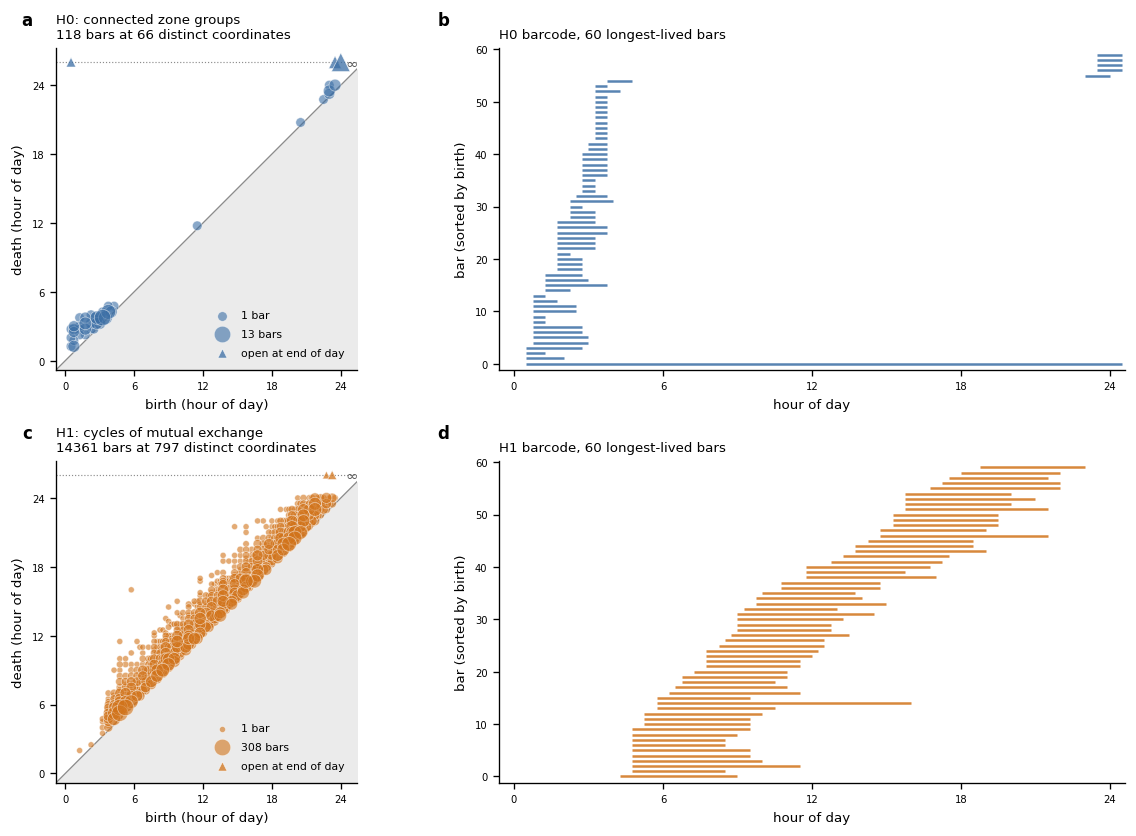

In [17]:
fig3, axes = plt.subplots(2, 2, figsize=(10.5, 7))

INF_Y = 26.0     # essential classes sit on a line above the finite range

for row, d in enumerate((0, 1)):
    sub = bars[bars.dim == d]
    col = CLR["h0"] if d == 0 else CLR["h1"]

    # --- classical persistence diagram (axes are TIME, not distance) ----------
    # Births and deaths land on the discrete window grid, so 14k H1 bars occupy
    # only a few hundred distinct coordinates. Plotting multiplicity as marker
    # area is the standard way to show that without overplotting.
    ax = axes[row, 0]
    ax.fill_between([-1, INF_Y + 1], [-1, INF_Y + 1], -1,
                    color="0.92", zorder=0, linewidth=0)      # forbidden region
    ax.plot([-1, INF_Y + 1], [-1, INF_Y + 1], lw=.8, color="0.55", zorder=1)

    closed, opn = sub[~sub.open], sub[sub.open]
    mult = (closed.groupby(["birth_h", "death_h"]).size()
            .reset_index(name="n").sort_values("n"))
    smax = max(mult.n.max(), 1)
    msize = lambda n: 8 + 90 * np.sqrt(np.asarray(n) / smax)   # area ~ multiplicity
    ax.scatter(mult.birth_h, mult.death_h, s=msize(mult.n),
               color=col, alpha=.6, edgecolor="white", linewidth=.4, zorder=3)

    if len(opn):
        ax.axhline(INF_Y, lw=.7, ls=":", color="0.55", zorder=1)
        om = opn.groupby("birth_h").size().reset_index(name="n")
        ax.scatter(om.birth_h, np.full(len(om), INF_Y), s=msize(om.n), marker="^",
                   color=col, alpha=.75, edgecolor="white", linewidth=.4, zorder=4)
        ax.text(24.4, INF_Y, r"$\infty$", va="center", ha="left", fontsize=9, color="0.35")

    # Marker-size key: two round multiplicities spanning the observed range.
    keys = sorted({1, int(smax)}) if smax > 1 else [1]
    handles = [ax.scatter([], [], s=msize(k), color=col, alpha=.6, edgecolor="white",
                          linewidth=.4, label=f"{k} bar" + "s" * (k > 1)) for k in keys]
    if len(opn):
        handles.append(ax.scatter([], [], s=30, marker="^", color=col, alpha=.75,
                                  edgecolor="white", linewidth=.4, label="open at end of day"))
    ax.legend(handles=handles, loc="lower right", labelspacing=.8,
              borderpad=.6, handletextpad=.8, fontsize=6.5)

    ax.set_xlabel("birth (hour of day)"); ax.set_ylabel("death (hour of day)")
    ax.set_title(f"H{d}: {'connected zone groups' if d == 0 else 'cycles of mutual exchange'}\n"
                 f"{len(sub)} bars at {mult.shape[0] + len(opn)} distinct coordinates")
    ax.set_xlim(-.8, 25.4); ax.set_ylim(-.8, INF_Y + 1.2)
    ax.set_xticks(range(0, 25, 6)); ax.set_yticks(range(0, 25, 6))
    ax.set_aspect("equal", adjustable="box")

    # --- barcode (easier to read temporally) ---
    ax = axes[row, 1]
    show = sub.head(60).sort_values("birth_h").reset_index(drop=True)
    for i, r_ in show.iterrows():
        ax.plot([r_.birth_h, r_.death_h], [i, i], lw=1.5,
                color=col, alpha=.85, solid_capstyle="butt")
    ax.set_xlabel("hour of day"); ax.set_ylabel("bar (sorted by birth)")
    ax.set_title(f"H{d} barcode, {len(show)} longest-lived bars")
    ax.set_xlim(-.6, 24.6); ax.set_xticks(range(0, 25, 6))
    ax.margins(y=0.02)

for a, l in zip(axes.ravel(), "abcd"):
    panel_letter(a, l)
fig3.tight_layout()
fig3.savefig(OUT_DIR / "fig_zigzag_diagrams.png", dpi=300, bbox_inches="tight")

## 7. What the zigzag adds over per-snapshot statistics

Myers' central claim is that the zigzag carries information that per-snapshot
summary statistics cannot: **feature identity across windows**. A Betti curve
says *how many* components exist at 08:00 and at 09:00; it cannot say whether
they are the *same* components. A zigzag bar can.

The comparison below computes, per snapshot, the standard temporal-network
descriptors (component count, mean degree, mean betweenness / closeness) plus the
static Betti numbers of the same complex, and plots them on the same hour-of-day
axis as the barcode.

Betweenness is estimated with `k = 80` pivot nodes; exact betweenness on 48
graphs of ~540 nodes is unnecessary for a shape comparison.

In [18]:
BETWEEN_PIVOTS = 80
rng_seed = 0

def snapshot_graph(start):
    G = nx.Graph(); G.add_edges_from(window_edges(start, start + WINDOW_MIN))
    return G

def static_betti(K, max_dim=MAX_DIM):
    st = gudhi.SimplexTree()
    for s in K:
        st.insert(list(s), 0.0)
    st.compute_persistence(persistence_dim_max=False)
    b = list(st.betti_numbers())
    return b + [0] * (max_dim + 1 - len(b))

t0 = time.time()
rows = []
for start, K in zip(starts, Ks):
    G = snapshot_graph(start)
    n = G.number_of_nodes()
    b = static_betti(K)
    if n:
        comps = [len(c) for c in nx.connected_components(G)]
        k = min(BETWEEN_PIVOTS, n)
        btw = nx.betweenness_centrality(G, k=k, seed=rng_seed) if n > 2 else {}
        rows.append(dict(
            window_start_min=start, hour=(start + WINDOW_MIN / 2) / 60,
            n_components=len(comps), largest_component=max(comps),
            frac_in_largest=max(comps) / n,
            mean_degree=2 * G.number_of_edges() / n,
            mean_betweenness=np.mean(list(btw.values())) if btw else 0.0,
            mean_closeness=np.mean(list(nx.closeness_centrality(G).values())),
            betti_0=b[0], betti_1=b[1]))
    else:
        rows.append(dict(window_start_min=start, hour=(start + WINDOW_MIN / 2) / 60,
                         n_components=0, largest_component=0, frac_in_largest=np.nan,
                         mean_degree=0.0, mean_betweenness=0.0, mean_closeness=0.0,
                         betti_0=0, betti_1=0))

netstats = pd.DataFrame(rows)
netstats.to_csv(OUT_DIR / "network_stats.csv", index=False)
print("computed in %.1fs" % (time.time() - t0))
print(netstats[["hour", "n_components", "largest_component", "mean_degree",
                "betti_0", "betti_1"]].to_string(index=False))

computed in 10.4s
 hour  n_components  largest_component  mean_degree  betti_0  betti_1
  0.5             4                  2     1.000000        4        0
  1.0            14                  8     1.176471       14        0
  1.5            14                 17     1.422222       14        0
  2.0            22                 26     1.435897       22        0
  2.5            24                 27     1.454545       24        0
  3.0            25                 54     1.622951       25        0
  3.5            33                100     1.730570       33        5
  4.0            14                322     2.957020       14      163
  4.5             3                432     4.770642        3      516
  5.0             1                508    10.236220        1     1110
  5.5             1                534    15.880150        1     1155
  6.0             1                540    24.425926        1      749
  6.5             1                540    28.262963        1      574
  

### Figure 4 — per-snapshot statistics against the zigzag barcode

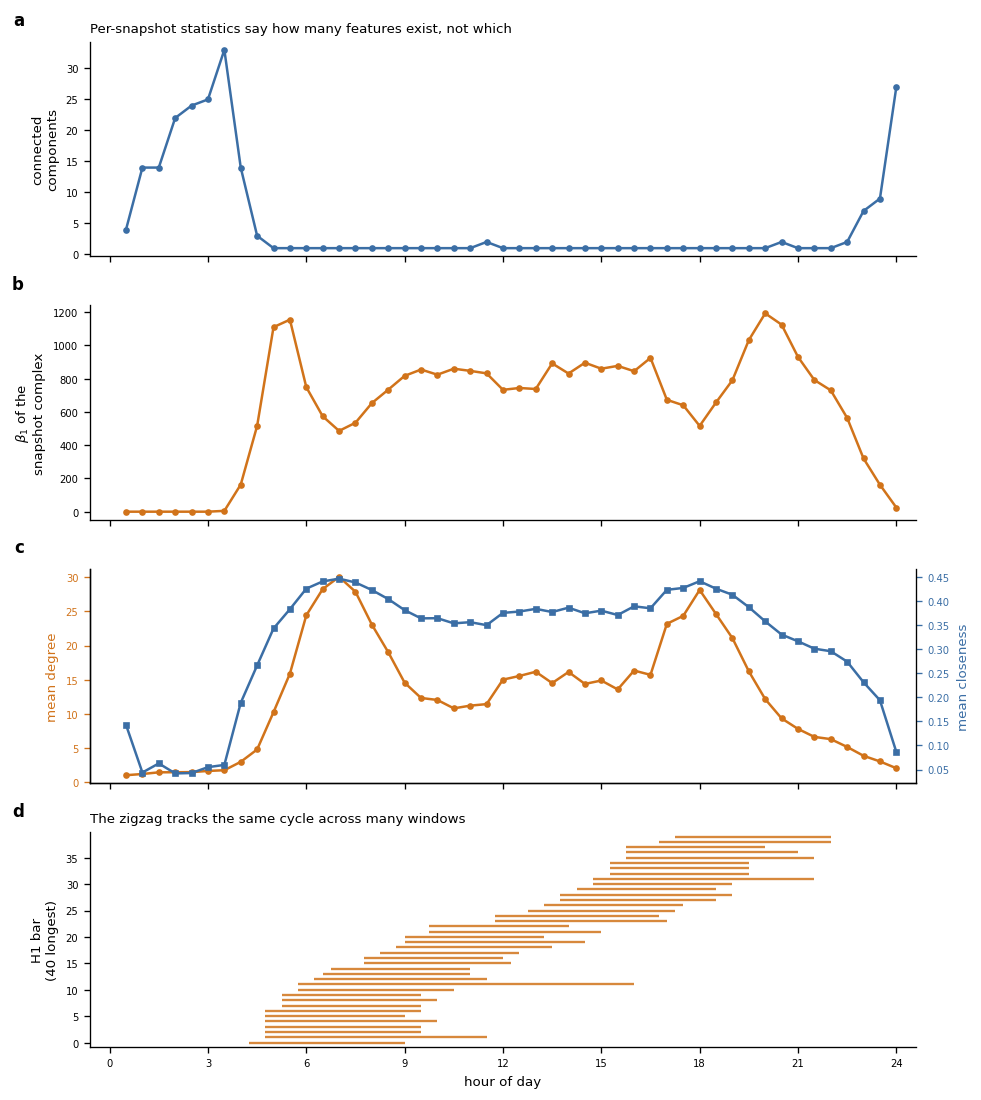

In [19]:
fig4, axes = plt.subplots(4, 1, figsize=(8.2, 9.2), sharex=True)

ax = axes[0]
ax.plot(netstats.hour, netstats.n_components, "o-", ms=3, color=CLR["h0"])
ax.set_ylabel("connected\ncomponents")
ax.set_title("Per-snapshot statistics say how many features exist, not which")
ax.margins(0.04)

ax = axes[1]
ax.plot(netstats.hour, netstats.betti_1, "o-", ms=3, color=CLR["h1"])
ax.set_ylabel(r"$\beta_1$ of the"  "\nsnapshot complex")
ax.margins(0.04)

ax = axes[2]
# Grey reads as de-emphasis, but this curve is one of the two the panel is about;
# give it the H1 hue and bind each axis label to its own curve's colour.
ax.plot(netstats.hour, netstats.mean_degree, "o-", ms=3, color=CLR["h1"])
ax.set_ylabel("mean degree", color=CLR["h1"])
ax.tick_params(axis="y", colors=CLR["h1"])
ax2 = ax.twinx()
ax2.plot(netstats.hour, netstats.mean_closeness, "s-", ms=3, color=CLR["h0"])
ax2.set_ylabel("mean closeness", color=CLR["h0"])
ax2.tick_params(axis="y", colors=CLR["h0"]); ax2.spines["right"].set_visible(True)
ax.margins(0.04)

ax = axes[3]
show = bars[bars.dim == 1].head(40).sort_values("birth_h").reset_index(drop=True)
for i, r_ in show.iterrows():
    ax.plot([r_.birth_h, r_.death_h], [i, i], lw=1.4, color=CLR["h1"],
            alpha=.85, solid_capstyle="butt")
ax.set_ylabel("H1 bar\n(40 longest)"); ax.set_xlabel("hour of day")
ax.set_title("The zigzag tracks the same cycle across many windows")
ax.set_xticks(range(0, 25, 3)); ax.set_xlim(-.6, 24.6); ax.margins(y=0.02)

for a, l in zip(axes, "abcd"):
    panel_letter(a, l)
fig4.tight_layout()
fig4.savefig(OUT_DIR / "fig_network_stats.png", dpi=300, bbox_inches="tight")

## 8. Where the features live

Myers explicitly flags generator extraction as unimplemented in their work. The
barcode used here likewise carries bars only, not representative cycles. So
localization is **indicative, not exact** — it identifies structures of the right
homology class in the relevant snapshots rather than the specific generator the
algorithm paired.

* **H0** is exact: components are computable directly, and a long H0 bar beyond
  the first *is* a specific set of zones that stayed separate.
* **H1** is indicative: a chordless cycle of length ≥ 4 is never filled by the
  2-skeleton at `RIPS_R = 1`, so it carries a genuine H1 class. Cycles present in
  every window a bar spans are the plausible carriers of that bar.

In [20]:
zones = gpd.read_file(ZONES_SHP)
zones["SIT_2017"] = zones.SIT_2017.astype(int)
# Reproject to MAGNA-SIRGAS / Colombia West (EPSG:3115) so centroids are metric.
print("source CRS:", zones.crs)
zones = zones.to_crs(3115)

matched = set(zones.SIT_2017) & set(zones_all)
print(f"shapefile polygons: {len(zones)} | trip zones: {len(zones_all)} | matched: {len(matched)}")
print("trip zones with no polygon:", sorted(set(zones_all) - set(zones.SIT_2017)))

source CRS: EPSG:4326
shapefile polygons: 536 | trip zones: 544 | matched: 533
trip zones with no polygon: [800, 801, 802, 803, 804, 805, 806, 807, 810, 811, 812]


In [21]:
def fragmented_zones(start):
    """Zones outside the largest component of a snapshot -- the carriers of extra H0 bars."""
    G = snapshot_graph(start)
    if G.number_of_nodes() == 0:
        return set()
    comps = sorted(nx.connected_components(G), key=len, reverse=True)
    return set().union(*comps[1:]) if len(comps) > 1 else set()

# Count, per zone, how many windows it spent detached from the metropolitan core.
frag_count = Counter()
for s in starts:
    frag_count.update(fragmented_zones(s))
frag = pd.Series(frag_count, name="windows_detached").rename_axis("SIT_2017").reset_index()
frag.to_csv(OUT_DIR / "h0_fragmentation_by_zone.csv", index=False)
print("zones ever detached from the largest component:", len(frag))
print(frag.sort_values("windows_detached", ascending=False).head(10).to_string(index=False))

zones ever detached from the largest component: 240
 SIT_2017  windows_detached
      131                 7
      337                 6
       44                 5
      356                 5
      432                 5
       51                 5
       76                 5
       18                 5
      348                 5
      158                 5


In [2]:
def indicative_h1_cycles(birth_min, death_min, max_len=6, topk=6):
    """Chordless cycles (length 4..max_len) present in EVERY window the bar spans.

    A chordless cycle is not filled by the 2-skeleton at RIPS_R=1, so it carries H1.
    """
    spanned = [s for s in starts if birth_min <= s + WINDOW_MIN / 2 <= death_min]
    if not spanned:
        return [], []
    graphs = [snapshot_graph(s) for s in spanned]
    common = set.intersection(*[{tuple(sorted(e)) for e in g.edges} for g in graphs])
    Gc = nx.Graph(list(common))
    out = []
    for c in nx.chordless_cycles(Gc, length_bound=max_len):
        if len(c) >= 4:
            out.append([int(x) for x in c])
        if len(out) >= topk:
            break
    return spanned, out

top_h1 = bars[bars.dim == 1].iloc[0]
spanned, cycles = indicative_h1_cycles(top_h1.birth_min, top_h1.death_min)
print("longest H1 bar: %.1fh -> %.1fh (%.1f h), spans %d windows"
      % (top_h1.birth_h, top_h1.death_h, top_h1.persistence_h, len(spanned)))
print("persistently-present chordless cycles (length>=4):", len(cycles))
for c in cycles:
    print("   ", c)

# Fall back to the birth snapshot when no cycle survives every spanned window.
if not cycles:
    Gb = snapshot_graph(int(top_h1.birth_min - WINDOW_MIN / 2))
    cycles = [[int(x) for x in c] for c in itertools.islice(
        (c for c in nx.chordless_cycles(Gb, length_bound=5) if len(c) >= 4), 6)]
    print("\nno cycle survives every window; showing birth-snapshot cycles instead:")
    for c in cycles:
        print("   ", c)

NameError: name 'bars' is not defined

### Figure 5 — geography of the persistent features

In [1]:
zg = zones.merge(frag, on="SIT_2017", how="left")
zg["windows_detached"] = zg.windows_detached.fillna(0)
cent = zones.set_index("SIT_2017").geometry.centroid

# The metro area mixes very large rural zones with very small urban ones, so the
# urban core needs its own panel or the fragmentation signal is invisible.
urban = zg[zg.geometry.area < zg.geometry.area.quantile(.75)]
ux0, uy0, ux1, uy1 = urban.total_bounds
pad = 0.05 * max(ux1 - ux0, uy1 - uy0)

fig5, axes = plt.subplots(1, 3, figsize=(13.5, 4.8))

vmax = zg.windows_detached.max()
for ax, (title, zoom) in zip(axes[:2], [
        ("Whole metropolitan area", None),
        ("Medellín urban core (detail)", (ux0 - pad, ux1 + pad, uy0 - pad, uy1 + pad))]):
    zg.plot(column="windows_detached", ax=ax, cmap="YlOrRd", vmin=0, vmax=vmax,
            linewidth=.15, edgecolor="white", legend=(zoom is None),
            legend_kwds={"label": "windows detached from the core", "shrink": .5})
    if zoom:
        ax.set_xlim(zoom[0], zoom[1]); ax.set_ylim(zoom[2], zoom[3])
    ax.set_axis_off()
    ax.set_title(title)
axes[0].set_title("Zones detached from the core: whole metropolitan area")
axes[1].set_title(f"Urban core detail — {len(frag)} of {len(zones_all)} zones\n"
                  f"detach in at least one window")

# Panel c: zoom to the indicative H1 carriers and label the zones.
ax = axes[2]
shown = cycles[:2]
zone_ids = sorted({z for c in shown for z in c})
sub = zg[zg.SIT_2017.isin(zone_ids)]
if len(sub):
    cx0, cy0, cx1, cy1 = sub.total_bounds
    cpad = 0.12 * max(cx1 - cx0, cy1 - cy0, 1)
    zg.plot(ax=ax, color="#F7F7F7", linewidth=.2, edgecolor="white")
    sub.plot(ax=ax, color="#FBE3D0", linewidth=.6, edgecolor=CLR["h1"])
    for c, style in zip(shown, ["-", "--"]):
        pts = [cent[z] for z in c if z in cent.index]
        if len(pts) == len(c):
            xs = [p.x for p in pts] + [pts[0].x]
            ys = [p.y for p in pts] + [pts[0].y]
            ax.plot(xs, ys, style, marker="o", ms=5, lw=1.6, color=CLR["h1"], alpha=.9)
    for z in zone_ids:
        if z in cent.index:
            ax.annotate(str(z), (cent[z].x, cent[z].y), textcoords="offset points",
                        xytext=(5, 4), fontsize=7, color="#333333")
    ax.set_xlim(cx0 - cpad, cx1 + cpad); ax.set_ylim(cy0 - cpad, cy1 + cpad)
ax.set_axis_off()
ax.set_title(f"Indicative carriers of the longest H1 bar\n"
             f"({top_h1.birth_h:.1f}h–{top_h1.death_h:.1f}h, {top_h1.persistence_h:.1f} h persistence)")

for a, l in zip(axes, "abc"):
    panel_letter(a, l)
fig5.tight_layout()
fig5.savefig(OUT_DIR / "fig_persistent_features_map.png", dpi=300, bbox_inches="tight")

NameError: name 'zones' is not defined